# Построение модели для оценки кредитного риска #

In [58]:
import pickle
import warnings
import os
import gc
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tqdm

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import VotingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin


import lightgbm as lgb
from lightgbm import LGBMClassifier
import xgboost as xgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')   

## Ознакомление с одним файлом из тренировочного датасета

In [80]:
train_data_0 = pd.read_parquet('train_data/train_data_0.pq')   

In [81]:
train_data_0.head() 

,id,rn,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,...,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag
0,0,1,18,9,2,3,16,10,11,3,...,3,3,3,4,1,3,4,1,0,0
1,0,2,18,9,14,14,12,12,0,3,...,0,0,0,4,1,3,4,1,0,0
2,0,3,18,9,4,8,1,11,11,0,...,0,0,0,4,1,2,3,1,1,1
3,0,4,4,1,9,12,16,7,12,2,...,3,3,3,4,1,3,1,1,0,0
4,0,5,5,12,15,2,11,12,10,2,...,3,3,3,4,1,3,4,1,0,0


In [82]:
print("Размер:")
train_data_0.shape 

Размер:


(1974724, 61)

In [83]:
train_data_0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1974724 entries, 0 to 1974723
Data columns (total 61 columns):
 #   Column                         Dtype
---  ------                         -----
 0   id                             int64
 1   rn                             int64
 2   pre_since_opened               int64
 3   pre_since_confirmed            int64
 4   pre_pterm                      int64
 5   pre_fterm                      int64
 6   pre_till_pclose                int64
 7   pre_till_fclose                int64
 8   pre_loans_credit_limit         int64
 9   pre_loans_next_pay_summ        int64
 10  pre_loans_outstanding          int64
 11  pre_loans_total_overdue        int64
 12  pre_loans_max_overdue_sum      int64
 13  pre_loans_credit_cost_rate     int64
 14  pre_loans5                     int64
 15  pre_loans530                   int64
 16  pre_loans3060                  int64
 17  pre_loans6090                  int64
 18  pre_loans90                    int64
 19  

In [84]:
print("Типы колонок:")
train_data_0.dtypes.value_counts() 

Типы колонок:


int64    61
Name: count, dtype: int64

In [85]:
# Проверка на пропуски:
print(f'Пропусков: {train_data_0.isnull().sum().sum()}') 

Пропусков: 0


In [86]:
# проверяю диапазоны значений в колонках
for col in train_data_0.columns:
    min_val = train_data_0[col].min()
    max_val = train_data_0[col].max()
    print(f'{col}: min={min_val}, max={max_val}')  

id: min=0, max=249999
rn: min=1, max=51
pre_since_opened: min=0, max=19
pre_since_confirmed: min=0, max=17
pre_pterm: min=0, max=17
pre_fterm: min=0, max=16
pre_till_pclose: min=0, max=16
pre_till_fclose: min=0, max=15
pre_loans_credit_limit: min=0, max=19
pre_loans_next_pay_summ: min=0, max=6
pre_loans_outstanding: min=1, max=5
pre_loans_total_overdue: min=0, max=0
pre_loans_max_overdue_sum: min=1, max=3
pre_loans_credit_cost_rate: min=0, max=13
pre_loans5: min=0, max=16
pre_loans530: min=0, max=18
pre_loans3060: min=2, max=9
pre_loans6090: min=1, max=4
pre_loans90: min=8, max=19
is_zero_loans5: min=0, max=1
is_zero_loans530: min=0, max=1
is_zero_loans3060: min=0, max=1
is_zero_loans6090: min=0, max=1
is_zero_loans90: min=0, max=1
pre_util: min=0, max=19
pre_over2limit: min=0, max=19
pre_maxover2limit: min=0, max=19
is_zero_util: min=0, max=1
is_zero_over2limit: min=0, max=1
is_zero_maxover2limit: min=0, max=1
enc_paym_0: min=0, max=3
enc_paym_1: min=0, max=3
enc_paym_2: min=0, max=3


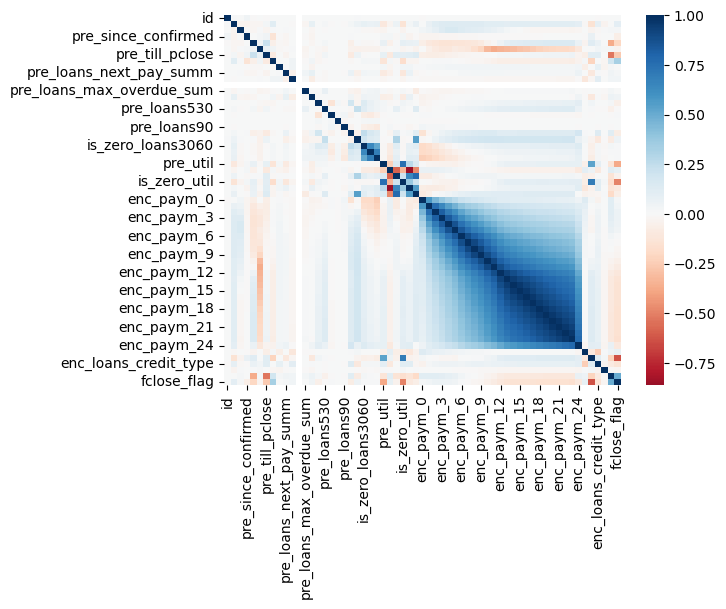

In [9]:
# Посмотрим на корреляции между признаками: 
corr_matrix = train_data_0.corr()
sns.heatmap(corr_matrix,  cmap='RdBu', center=0);  

In [10]:
# посмотрю пары с положительной корреляцией больше 0.85
high_corr = np.where(corr_matrix > 0.85)
high_corr_pairs = [(corr_matrix.index[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]) 
                   for i, j in zip(*high_corr) if i < j]

print(f'Пар с корреляцией > 0.85: {len(high_corr_pairs)}')
for f1, f2, val in high_corr_pairs: 
    print(f'  {f1} - {f2}: {val:.3f}')  

Пар с корреляцией > 0.85: 43
  enc_paym_4 - enc_paym_5: 0.867
  enc_paym_6 - enc_paym_7: 0.887
  enc_paym_7 - enc_paym_8: 0.906
  enc_paym_8 - enc_paym_9: 0.914
  enc_paym_9 - enc_paym_10: 0.894
  enc_paym_10 - enc_paym_11: 0.911
  enc_paym_11 - enc_paym_12: 0.886
  enc_paym_12 - enc_paym_13: 0.922
  enc_paym_12 - enc_paym_14: 0.879
  enc_paym_13 - enc_paym_14: 0.948
  enc_paym_13 - enc_paym_15: 0.913
  enc_paym_13 - enc_paym_16: 0.881
  enc_paym_13 - enc_paym_17: 0.852
  enc_paym_14 - enc_paym_15: 0.956
  enc_paym_14 - enc_paym_16: 0.922
  enc_paym_14 - enc_paym_17: 0.891
  enc_paym_14 - enc_paym_18: 0.857
  enc_paym_15 - enc_paym_16: 0.959
  enc_paym_15 - enc_paym_17: 0.925
  enc_paym_15 - enc_paym_18: 0.889
  enc_paym_15 - enc_paym_19: 0.860
  enc_paym_16 - enc_paym_17: 0.960
  enc_paym_16 - enc_paym_18: 0.921
  enc_paym_16 - enc_paym_19: 0.891
  enc_paym_16 - enc_paym_20: 0.864
  enc_paym_17 - enc_paym_18: 0.954
  enc_paym_17 - enc_paym_19: 0.922
  enc_paym_17 - enc_paym_20: 0.894


*Бинарные признаки содержат только значения 0 и 1.
enc_  признаки в диапозоне от 0 до 6.
Остальные признаки имеют диапазон значений от 0 до 19.
Пропуски отсутствуют, аномальных значений нет.* 

## Анализ целевой переменной

In [11]:
# Загружаем target
target = pd.read_csv('train_target.csv') 

In [12]:
print(target.head())   

   id  flag
0   0     0
1   1     0
2   2     0
3   3     0
4   4     0


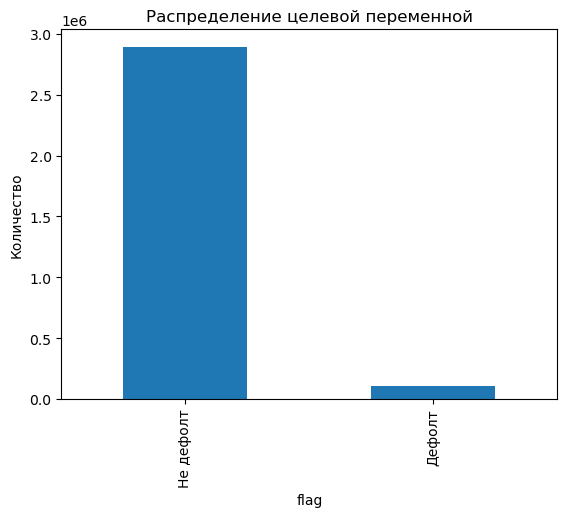

In [13]:
target['flag'].value_counts().plot(kind='bar')
plt.title('Распределение целевой переменной')
plt.xticks([0, 1], ['Не дефолт', 'Дефолт'])
plt.ylabel('Количество')
plt.show() 

In [14]:
print(target.shape)
print(target['flag'].value_counts())
print(f'Доля дефолтов: {target["flag"].mean() * 100:.2f}%')      

(3000000, 2)
flag
0    2893558
1     106442
Name: count, dtype: int64
Доля дефолтов: 3.55%


*Выборка сильно несбалансирована: дефолтов только 3,55%, при обучении модели нужно будет учитывать дисбаланс.*

## Моделирование новых признаков, OHE, агрегация, мердж с таргет

In [87]:
# Количество кредитов у клиента(от 1 до 51)

train_data_0['credit_count'] = train_data_0.groupby('id')['rn'].transform('count') 

In [88]:
# чтобы не было слишком много колонок, удалю признаки, которые почти дублируют друг друга
unique_features = set()
for f1, f2, val in high_corr_pairs:
    unique_features.add(f1)
    unique_features.add(f2)

print(f'Всего признаков с высокой корреляцией: {len(unique_features)}')
print(sorted(unique_features))

Всего признаков с высокой корреляцией: 20
['enc_paym_10', 'enc_paym_11', 'enc_paym_12', 'enc_paym_13', 'enc_paym_14', 'enc_paym_15', 'enc_paym_16', 'enc_paym_17', 'enc_paym_18', 'enc_paym_19', 'enc_paym_20', 'enc_paym_21', 'enc_paym_22', 'enc_paym_23', 'enc_paym_4', 'enc_paym_5', 'enc_paym_6', 'enc_paym_7', 'enc_paym_8', 'enc_paym_9']


In [89]:
to_remove = [f'enc_paym_{i}' for i in range(4, 24)]
train_data_0 = train_data_0.drop(columns=to_remove) 

In [90]:
# rn больше не нужен, есть credit_count, удаляю
train_data_0 = train_data_0.drop('rn', axis=1) 

In [91]:
# pre_loans_total_overdue константа 0, удаляю
train_data_0 = train_data_0.drop('pre_loans_total_overdue', axis=1)  

In [92]:
train_data_0.shape 

(1974724, 40)

In [93]:
# Бинарные признаки, для них не буду делать OHE:
binary_features = [col for col in train_data_0.columns if train_data_0[col].nunique() == 2]
print(binary_features)  

['is_zero_loans5', 'is_zero_loans530', 'is_zero_loans3060', 'is_zero_loans6090', 'is_zero_loans90', 'is_zero_util', 'is_zero_over2limit', 'is_zero_maxover2limit', 'pclose_flag', 'fclose_flag']


In [94]:
# Колонки для OHE:
# Cюда очевидно включаю закодированные признаки nc_paym_
# pre_ признаки были бинаризированы, номера промежутков присвоены случайным образом, поэтому их тоже можно считать категориями

exclude_cols = ['id', 'credit_count'] + binary_features
ohe_features = [col for col in train_data_0.columns if col not in exclude_cols]

print(f'Колонки для OHE ({len(ohe_features)}):')
print(ohe_features)  

Колонки для OHE (28):
['pre_since_opened', 'pre_since_confirmed', 'pre_pterm', 'pre_fterm', 'pre_till_pclose', 'pre_till_fclose', 'pre_loans_credit_limit', 'pre_loans_next_pay_summ', 'pre_loans_outstanding', 'pre_loans_max_overdue_sum', 'pre_loans_credit_cost_rate', 'pre_loans5', 'pre_loans530', 'pre_loans3060', 'pre_loans6090', 'pre_loans90', 'pre_util', 'pre_over2limit', 'pre_maxover2limit', 'enc_paym_0', 'enc_paym_1', 'enc_paym_2', 'enc_paym_3', 'enc_paym_24', 'enc_loans_account_holder_type', 'enc_loans_credit_status', 'enc_loans_credit_type', 'enc_loans_account_cur']


In [95]:
df_ohe = pd.DataFrame()

# Применяем OHE к ohe_features
encoder = OneHotEncoder(sparse_output=False)
ohe_array = encoder.fit_transform(train_data_0[ohe_features])

# df  с OHE колонками
ohe_columns = encoder.get_feature_names_out(ohe_features)
df_ohe = pd.DataFrame(ohe_array, columns=ohe_columns, index=train_data_0.index)

# id, credit_count и бинарные колонки
for col in ['id', 'credit_count'] + binary_features:
    df_ohe[col] = train_data_0[col]

print(f'Размер df_ohe: {df_ohe.shape}')
print(f'Колонки: {df_ohe.columns.tolist()[:10]}...')  

Размер df_ohe: (1974724, 306)
Колонки: ['pre_since_opened_0', 'pre_since_opened_1', 'pre_since_opened_2', 'pre_since_opened_3', 'pre_since_opened_4', 'pre_since_opened_5', 'pre_since_opened_6', 'pre_since_opened_7', 'pre_since_opened_8', 'pre_since_opened_9']...


In [96]:
# Агрегация по id : сумма для OHE и бинарных, max для credit_count
agg_cols = [col for col in df_ohe.columns if col != 'id']
agg_dict = {col: 'sum' for col in agg_cols if col != 'credit_count'}
agg_dict['credit_count'] = 'max'

df_agg = df_ohe.groupby('id').agg(agg_dict).reset_index()

print(f'Размер после агрегации: {df_agg.shape}') 

Размер после агрегации: (250000, 306)


In [97]:
# Мердж с target
df_agg = df_agg.merge(target, on='id', how='left')

print(f'Размер после мерджа: {df_agg.shape}')  

Размер после мерджа: (250000, 307)


## Эксперименты с моделями, отбор важных признаков 


### RandomForest 



In [98]:
# Признаки и целевая
X = df_agg.drop(['id', 'flag'], axis=1)
y = df_agg['flag']

# Разделение
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)  

In [99]:
# rf
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced', max_depth=6)
rf.fit(X_train, y_train) 

# ROC-AUC на тесте
y_pred = rf.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred)
print(f'ROC-AUC на тесте: {auc:.4f}') 

ROC-AUC на тесте: 0.7205


In [100]:
# Важность признаков
importance = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_}).sort_values('importance', ascending=False)

print('Топ 20 признаков:')
print(importance.head(20))

# Отбираем признаки с важностью > 0
top_features = importance[importance['importance'] > 0]['feature'].tolist()
print(f'Отобрано признаков: {len(top_features)}')  

Топ 20 признаков:
                          feature  importance
262                  enc_paym_3_0    0.044059
147  pre_loans_credit_cost_rate_6    0.041480
255                  enc_paym_1_1    0.041475
258                  enc_paym_2_0    0.041394
254                  enc_paym_1_0    0.037836
193                    pre_util_3    0.034174
289       enc_loans_credit_type_5    0.033579
251                  enc_paym_0_1    0.032421
196                    pre_util_6    0.032158
108      pre_loans_credit_limit_2    0.030875
12            pre_since_opened_12    0.030109
263                  enc_paym_3_1    0.028809
284       enc_loans_credit_type_0    0.027953
259                  enc_paym_2_1    0.023449
295              is_zero_loans530    0.020807
138   pre_loans_max_overdue_sum_1    0.020608
250                  enc_paym_0_0    0.018869
233           pre_maxover2limit_3    0.018023
206                   pre_util_16    0.017825
265                  enc_paym_3_3    0.016684
Отобрано признак

In [102]:
# Попробую разное количество признаков
for n in [20, 50, 70, 150]:
    top_n = importance.head(n)['feature'].tolist()
    X_train_n = X_train[top_n]
    X_test_n = X_test[top_n]
    
    rf_n = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    rf_n.fit(X_train_n, y_train)
    y_pred_n = rf_n.predict_proba(X_test_n)[:, 1]
    auc_n = roc_auc_score(y_test, y_pred_n)
    print(f'Топ-{n}: ROC-AUC = {auc_n:.4f}')  

Топ-20: ROC-AUC = 0.6658
Топ-50: ROC-AUC = 0.6857
Топ-70: ROC-AUC = 0.6968
Топ-150: ROC-AUC = 0.7009


In [103]:
zero_importance = importance[importance['importance'] == 0]['feature'].tolist()
print(f'Признаков с нулевой важностью: {len(zero_importance)}')
print(zero_importance[:10]) 

Признаков с нулевой важностью: 47
['pre_loans530_4', 'pre_pterm_5', 'enc_loans_credit_status_6', 'pre_loans3060_7', 'pre_loans3060_2', 'pre_loans530_15', 'pre_loans530_11', 'pre_loans530_10', 'pre_loans530_7', 'pre_loans530_6']


In [104]:
# Удаляем их из X_train и X_test
X_train_clean = X_train.drop(columns=zero_importance)
X_test_clean = X_test.drop(columns=zero_importance) 

In [32]:
rf_clean = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced', max_depth=6)
rf_clean.fit(X_train_clean, y_train)

y_pred_clean = rf_clean.predict_proba(X_test_clean)[:, 1]
auc_clean = roc_auc_score(y_test, y_pred_clean)
print(f'ROC-AUC после удаления нулевых признаков: {auc_clean:.4f}') 

ROC-AUC после удаления нулевых признаков: 0.7220


### LogisticRegression

In [55]:
# с балансировкой классов
logreg_clean = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)

pipe_clean = Pipeline([
    ('scaler', StandardScaler()),
    ('model', logreg_clean)
])

pipe_clean.fit(X_train_clean, y_train)
y_pred_log_clean = pipe_clean.predict_proba(X_test_clean)[:, 1]
auc_log_clean = roc_auc_score(y_test, y_pred_log_clean)
print(f'LogisticRegression ROC-AUC : {auc_log_clean:.4f}')  

LogisticRegression ROC-AUC : 0.7473


### Light Gradient Boosting Machine

*class_weight='balanced' помогает модели с самого начала понимать, что дефолты важны, и не игнорировать их. В отличие от scale_pos_weight, который сохраняет реальный дисбаланс, class_weight='balanced' заставляет модель искать редкий класс активнее, что даёт лучший результат.*

In [108]:
# LightGBM

lgb = LGBMClassifier(
    n_estimators=200,
    max_depth=4,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)
lgb.fit(X_train_clean, y_train)
y_pred_lgb = lgb.predict_proba(X_test_clean)[:, 1]
auc_lgb = roc_auc_score(y_test, y_pred_lgb)
print(f'LightGBM ROC-AUC: {auc_lgb:.4f}')    

LightGBM ROC-AUC: 0.7509


In [68]:
param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.05, 0.1]
}

lgb = LGBMClassifier(n_estimators=200, class_weight='balanced', random_state=42, verbose=-1)

grid = GridSearchCV(lgb, param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train_clean, y_train)

print(f'Лучшие параметры: {grid.best_params_}')
print(f'Лучший ROC-AUC: {grid.best_score_:.4f}')

y_pred_best = grid.best_estimator_.predict_proba(X_test_clean)[:, 1]
print(f'ROC-AUC на тесте: {roc_auc_score(y_test, y_pred_best):.4f}')

Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 3}
Лучший ROC-AUC: 0.7555
ROC-AUC на тесте: 0.7542


In [70]:
best_lgb = LGBMClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42,
    verbose=-1
) 

### eXtreme Gradient Boosting 

In [57]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()


xgb = XGBClassifier( n_estimators=200, scale_pos_weight=pos_weight,
    random_state=42, use_label_encoder=False, eval_metric='logloss')

xgb.fit(X_train_clean, y_train)
y_pred_xgb = xgb.predict_proba(X_test_clean)[:, 1]
auc_xgb = roc_auc_score(y_test, y_pred_xgb)
print(f'XGBoost ROC-AUC: {auc_xgb:.4f}') 

XGBoost ROC-AUC: 0.6860


### Histogram-based Gradient Boosting Classification 

In [59]:
from sklearn.ensemble import HistGradientBoostingClassifier

In [60]:
hist = HistGradientBoostingClassifier(max_iter=200, max_depth=6, random_state=42)
hist.fit(X_train_clean, y_train)
y_pred_hist = hist.predict_proba(X_test_clean)[:, 1]
auc_hist = roc_auc_score(y_test, y_pred_hist)
print(f'HistGradientBoosting ROC-AUC: {auc_hist:.4f}') 

HistGradientBoosting ROC-AUC: 0.7473


In [69]:
param_grid = {
    'max_depth': [4, 5, 6],
    'learning_rate': [0.05, 0.1, 0.15],
    'max_iter': [200, 300]
}

hist = HistGradientBoostingClassifier(random_state=42)

grid = GridSearchCV(hist, param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train_clean, y_train)

print(f'Лучшие параметры: {grid.best_params_}')
print(f'Лучший ROC-AUC на валидации: {grid.best_score_:.4f}')

y_pred_best = grid.best_estimator_.predict_proba(X_test_clean)[:, 1]
print(f'ROC-AUC на тесте: {roc_auc_score(y_test, y_pred_best):.4f}') 

Лучшие параметры: {'learning_rate': 0.05, 'max_depth': 5, 'max_iter': 200}
Лучший ROC-AUC на валидации: 0.7561
ROC-AUC на тесте: 0.7493


### Categorical Boosting Classification 

In [63]:
cat = CatBoostClassifier(iterations=200, depth=6, random_state=42, verbose=False)
cat.fit(X_train_clean, y_train)
y_pred_cat = cat.predict_proba(X_test_clean)[:, 1]
auc_cat = roc_auc_score(y_test, y_pred_cat)
print(f'CatBoost ROC-AUC: {auc_cat:.4f}')

CatBoost ROC-AUC: 0.7402


### Попробую усреднить LightGBM и HistGradientBoosting 

In [67]:
# Берём уже обученные модели
y_pred_lgb = lgb.predict_proba(X_test_clean)[:, 1]
y_pred_hist = hist.predict_proba(X_test_clean)[:, 1]

# Усреднение
y_pred_avg = (y_pred_lgb + y_pred_hist) / 2
auc_avg = roc_auc_score(y_test, y_pred_avg)

print(f'LightGBM: {roc_auc_score(y_test, y_pred_lgb):.4f}')
print(f'HistGradientBoosting: {roc_auc_score(y_test, y_pred_hist):.4f}')
print(f'Усреднение LGB + Hist: {auc_avg:.4f}') 

LightGBM: 0.7509
HistGradientBoosting: 0.7473
Усреднение LGB + Hist: 0.7521


*LightGBM с подбором параметров показал лучший ROC-AUC среди одиночных моделей - 0.7509. Усреднение с другими моделями дало незначительный прирост, поэтому решено использовать LightGBM как основную, финальную модель .*

## Функции для чтения, обработки файлов и их объединения в итоговый датафрейм 

In [41]:
def read_parquet_dataset_from_local(path_to_dataset: str, start_from: int = 0,
                                     num_parts_to_read: int = 2, columns=None, verbose=False) -> pd.DataFrame:
  
    res = []
    dataset_paths = sorted([os.path.join(path_to_dataset, filename) for filename in os.listdir(path_to_dataset)
                              if filename.startswith('train_data')])
    
    start_from = max(0, start_from)
    chunks = dataset_paths[start_from: start_from + num_parts_to_read]
    
    for chunk_path in tqdm.tqdm_notebook(chunks, desc="Reading dataset with pandas"):
        chunk = pd.read_parquet(chunk_path, columns=columns)
        res.append(chunk)
    
    return pd.concat(res).reset_index(drop=True)    

In [42]:
def prepare_transactions_dataset(path_to_dataset: str, target_df: pd.DataFrame, 
                                 zero_importance_features=None,
                                 num_parts_to_preprocess_at_once: int = 2, 
                                 num_parts_total: int = 12,
                                 save_to_path=None, verbose: bool=False):
  
    preprocessed_frames = []
    encoder = None
    
    targets = target_df
    
    for step in tqdm.tqdm_notebook(range(0, num_parts_total, num_parts_to_preprocess_at_once),
                                   desc="Transforming transactions data"):
        # Читаем порцию 
        transactions_frame = read_parquet_dataset_from_local(path_to_dataset, step, 
                                                             num_parts_to_preprocess_at_once,
                                                             verbose=verbose)
        
        #препроцессинг
        
        # Удаляем pre_loans_total_overdue и enc_paym с 4 по 23
        transactions_frame = transactions_frame.drop(['pre_loans_total_overdue'] + [f'enc_paym_{i}' for i in range(4, 24)], axis=1, errors='ignore')
        
        
        # Создаём credit_count и удаляем rn
        transactions_frame['credit_count'] = transactions_frame.groupby('id')['rn'].transform('count')
        transactions_frame = transactions_frame.drop('rn', axis=1)
        
        # бинарные признаки
        binary_features = [col for col in transactions_frame.columns 
                          if transactions_frame[col].nunique() == 2 and col != 'id']
        
        # Колонки для OHE
        exclude_cols = ['id', 'credit_count'] + binary_features
        ohe_features = [col for col in transactions_frame.columns if col not in exclude_cols]
        
        # OHE
        if encoder is None:
            encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
            ohe_array = encoder.fit_transform(transactions_frame[ohe_features])
        else:
            ohe_array = encoder.transform(transactions_frame[ohe_features])
        
        ohe_columns = encoder.get_feature_names_out(ohe_features)
        ohe_df = pd.DataFrame(ohe_array, columns=ohe_columns, index=transactions_frame.index)
        
        # Собираем датафрейм
        df_result = pd.concat([transactions_frame[['id', 'credit_count'] + binary_features], ohe_df], axis=1)
        
        # Агрегация по id
        agg_cols = [col for col in df_result.columns if col != 'id']
        agg_dict = {col: 'sum' for col in agg_cols if col != 'credit_count'}
        agg_dict['credit_count'] = 'max'
        df_agg = df_result.groupby('id').agg(agg_dict).reset_index()
        
        # Мердж с target
        df_agg = df_agg.merge(targets, on='id', how='left')


         # удаление признаков с нулевой важностью
        if zero_importance_features is not None:
            to_drop = [col for col in zero_importance_features if col in df_agg.columns]
            df_agg = df_agg.drop(columns=to_drop)
      
        
        # Сохраняем в файл
        if save_to_path:
            os.makedirs(save_to_path, exist_ok=True)
            block_as_str = str(step)
            if len(block_as_str) == 1:
                block_as_str = '00' + block_as_str
            else:
                block_as_str = '0' + block_as_str
            df_agg.to_parquet(os.path.join(save_to_path, f'processed_chunk_{block_as_str}.parquet'))
        
        preprocessed_frames.append(df_agg)
        
        # Очищаем память
        del transactions_frame, ohe_df, df_result, df_agg
        gc.collect()
    
    # Объединяем все обработанные части
    final_df = pd.concat(preprocessed_frames, ignore_index=True)
    
    return final_df, encoder



In [43]:
# Обрабатываем все данные
data, encoder = prepare_transactions_dataset(
    path_to_dataset='train_data/',
    target_df=target,
    zero_importance_features=zero_importance, 
    num_parts_to_preprocess_at_once=1,
    num_parts_total=12,
    save_to_path='processed/',
    verbose=True
)

print(f'Итоговый размер: {data.shape}')
print(f'Доля дефолтов: {data["flag"].mean():.4f}') 

Transforming transactions data:   0%|          | 0/12 [00:00<?, ?it/s]

Reading dataset with pandas:   0%|          | 0/1 [00:00<?, ?it/s]

Reading dataset with pandas:   0%|          | 0/1 [00:00<?, ?it/s]

Reading dataset with pandas:   0%|          | 0/1 [00:00<?, ?it/s]

Reading dataset with pandas:   0%|          | 0/1 [00:00<?, ?it/s]

Reading dataset with pandas:   0%|          | 0/1 [00:00<?, ?it/s]

... (4 outputs left out)

Reading dataset with pandas:   0%|          | 0/1 [00:00<?, ?it/s]

Reading dataset with pandas:   0%|          | 0/1 [00:00<?, ?it/s]

Reading dataset with pandas:   0%|          | 0/1 [00:00<?, ?it/s]

Итоговый размер: (3000000, 260)
Доля дефолтов: 0.0355


## Финальная модель

In [75]:
# Признаки и целевая
X = data.drop(['id', 'flag'], axis=1)
y = data['flag']

# Разделение на train/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Лучшая модель
best_lgb = LGBMClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)

best_lgb.fit(X_train, y_train)

# Оценка
y_pred = best_lgb.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_pred)
print(f'ROC-AUC на тесте: {auc:.4f}')  

ROC-AUC на тесте: 0.7554


In [76]:
print(f'X shape: {X.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_pred shape: {y_pred.shape}')  

X shape: (3000000, 258)
X_test shape: (600000, 258)
y_pred shape: (600000,)


In [71]:
# проверяю на переобучение
y_train_pred = best_lgb.predict_proba(X_train)[:, 1]
y_test_pred = best_lgb.predict_proba(X_test)[:, 1]

# ROC-AUC
train_auc = roc_auc_score(y_train, y_train_pred)
test_auc = roc_auc_score(y_test, y_test_pred)

print(f'Разница: {train_auc - test_auc:.4f}')  

Разница: 0.0061


In [77]:
# сохраняем предсказания для теста
submission = pd.DataFrame({
    'id': data.iloc[X_test.index]['id'].values, 
    'flag': y_pred
})

submission.to_csv('submission.csv', index=False)
print(submission.head()) 


        id      flag
0  1176617  0.709732
1   385353  0.263297
2  1634546  0.462824
3  2895795  0.498421
4  2323499  0.422909


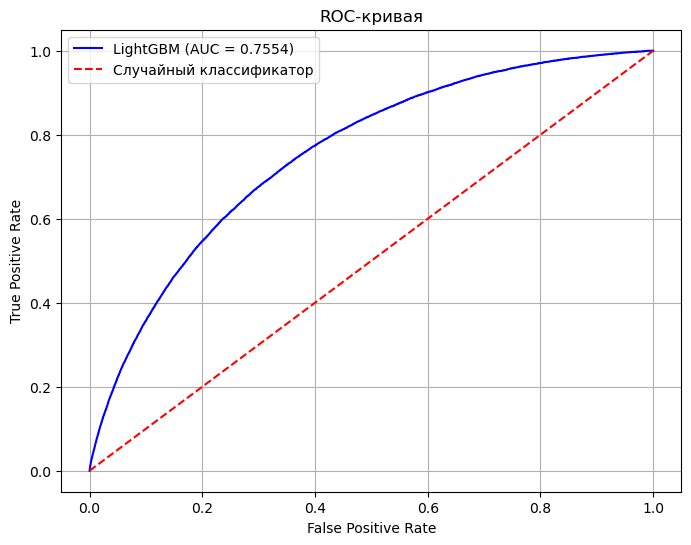

In [78]:
y_test_pred = best_lgb.predict_proba(X_test)[:, 1]

# ROC-кривая
fpr, tpr, thresholds = roc_curve(y_test, y_test_pred)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, 'b-', label=f'LightGBM (AUC = {test_auc:.4f})')
plt.plot([0, 1], [0, 1], 'r--', label='Случайный классификатор')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая')
plt.legend()
plt.grid(True)
plt.show() 

## Создание итогового пайплайна 

In [65]:
# проверка есть ли данные в памяти
if 'data' in globals():
    print(f"data уже загружена, размер: {data.shape}")
else:
    print(" Загружаем данные через prepare_transactions_dataset")
    data, encoder = prepare_transactions_dataset(
        path_to_dataset='train_data/',
        target_df=target,
        zero_importance_features=zero_importance,
        num_parts_to_preprocess_at_once=1,
        num_parts_total=12,
        save_to_path=None,
        verbose=True
    ) 

data уже загружена, размер: (3000000, 260)


In [66]:
final_pipeline = Pipeline([
    ('model', LGBMClassifier(
        n_estimators=500,
        max_depth=3,
        learning_rate=0.1,
        class_weight='balanced',
        random_state=42,
        verbose=-1
    ))
])
X_ready = data.drop(['id', 'flag'], axis=1)
y_ready = data['flag'] 

In [67]:
final_pipeline.fit(X_ready, y_ready)


,steps,"[('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,3
,learning_rate,0.1
,n_estimators,500
,subsample_for_bin,200000
,objective,None


In [68]:
joblib.dump(final_pipeline, 'final_pipeline.pkl') 


['final_pipeline.pkl']

In [70]:
# проверка
X_test_sample = X_ready[:5]

y_pred_proba = final_pipeline.predict_proba(X_test_sample)[:, 1]
y_pred_class = final_pipeline.predict(X_test_sample)

print("Вероятности дефолта:", y_pred_proba)
print("Классы:", y_pred_class) 

Вероятности дефолта: [0.11588866 0.47026719 0.67635984 0.43327769 0.62638189]
Классы: [0 0 1 0 1]
